# OCBench with a TD-MPC2 baseline

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/envs/ocbench.ipynb)

[OCBench](https://github.com/seohongpark/ocbench) is a controllable robotic manipulation benchmark of 28 UR5e + Robotiq 2F-85 tasks with paired Hugging Face datasets. Here the task is `block-lite-single-task1-v0`: pick up a block from a randomized pose and place it at a target pose from 28-dimensional state observations and 7 continuous arm and gripper controls, with a sparse reward of `1` upon success and episodes of up to 200 steps.

The baseline loads offline demonstrations with `load_ocbench`, trains a small [TD-MPC2](../../docs/models/tdmpc/tdmpc2.md) world model on 3-step action chunks with a behavior-cloned policy prior and conservative random-action value/reward targets, checks held-out multi-step latent dynamics, and plans in `OCBench` with MPPI and `RecedingHorizon`.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:
    %pip install -q "torch-world[examples,ocbench]"

In [1]:
import time

import torch
import torch.nn.functional as F
from torch.utils.data import ConcatDataset

from torch_world import plots
from torch_world.datasets import TrajectoryDataset, load_ocbench
from torch_world.envs import OCBench
from torch_world.models import TDMPC2
from torch_world.models.tdmpc import state_encoder
from torch_world.planning import MPPI, RecedingHorizon

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
TASK, CHUNK, HORIZON, ENVS = "block-lite-single-task1-v0", 3, 3, 16
world = OCBench(TASK, batch_size=ENVS, render_size=128)
EPISODE, A, D = world.max_episode_steps, world.action_dim, world.state.shape[-1]
A_CHUNK = A * CHUNK
print(f"{EPISODE}-step episodes, {D} state dimensions, {A} actions ({A_CHUNK} per {CHUNK}-step chunk), device={device}")

200-step episodes, 28 state dimensions, 7 actions (21 per 3-step chunk), device=mps


## The task and dataset

`load_ocbench` downloads the dataset shard once into `~/.cache/ocbench/datasets` and returns a list of variable-length episodes `(1, T, ...)` that plug directly into `TrajectoryDataset` via `ConcatDataset`. Because OCBench arm joint deltas are much smaller than the `[-1, 1]` gripper channel, we standardize observations and rescale arm controls by their 99.5th percentile while keeping the gripper in `[-1, 1]`. Four initial scenes from the simulator:

Using cached dataset: /Users/kcosta/.cache/ocbench/datasets/lite/block-lite-single-task1-v0 (1 training shards)


Using cached dataset: /Users/kcosta/.cache/ocbench/datasets/lite/block-lite-single-task1-v0 (1 training shards)
8000 successful train episodes (steps min/med/max: 22/64/200), 200 val episodes (14899 chunked windows)
action scales: [0.2226, 0.1792, 0.1984, 0.0908, 0.0047, 0.6172, 1.0]


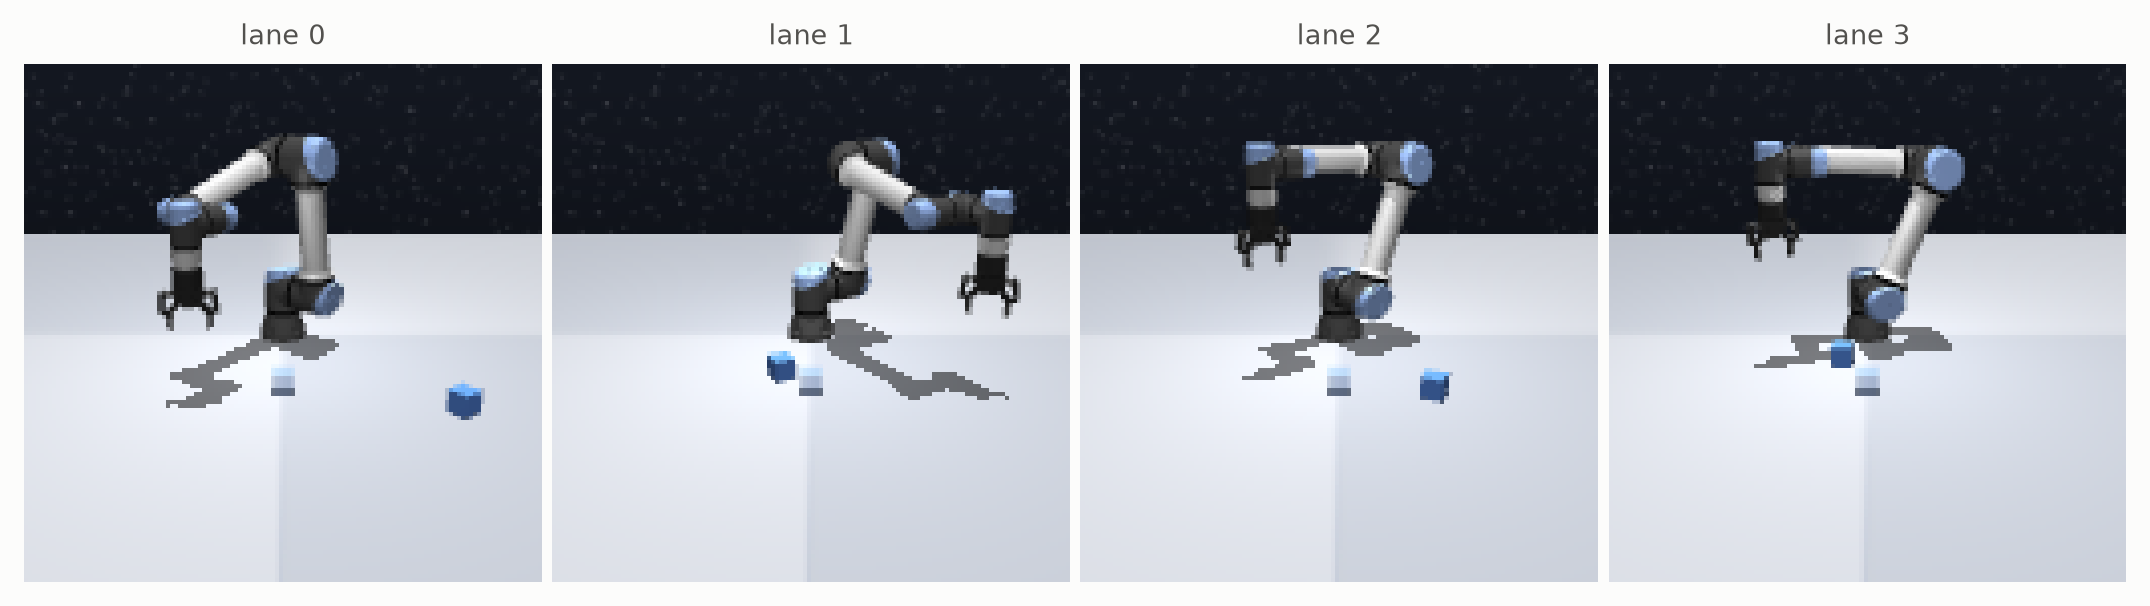

In [2]:
train_eps = load_ocbench(TASK, split="train", success_only=True, max_episodes=8000)
val_eps = load_ocbench(TASK, split="val", max_episodes=200)
lengths = sorted(ep["observations"].shape[1] - 1 for ep in train_eps)
val_windows = ConcatDataset(
    [
        TrajectoryDataset(ep, window=HORIZON + 1, frameskip=CHUNK)
        for ep in val_eps
        if ep["observations"].shape[1] >= (HORIZON + 1) * CHUNK
    ]
)
print(
    f"{len(train_eps)} successful train episodes (steps min/med/max: {lengths[0]}/{lengths[len(lengths) // 2]}/{lengths[-1]}), "
    f"{len(val_eps)} val episodes ({len(val_windows)} chunked windows)"
)

all_obs = torch.cat([ep["observations"][0] for ep in train_eps], dim=0)
obs_mean, obs_std = all_obs.mean(0), all_obs.std(0).clamp(min=1e-3)
all_act = torch.cat([ep["actions"][0, :-1] for ep in train_eps], dim=0)
act_scale = all_act.abs().quantile(0.995, dim=0).clamp(min=1e-3)
act_scale[-1] = 1.0
obs_mean_d, obs_std_d = obs_mean.to(device), obs_std.to(device)
print("action scales:", [round(x, 4) for x in act_scale.tolist()])

world.reset(seed=0)
plots.images(world.render_frame()[:4], [f"lane {i}" for i in range(4)], ncols=4, size=2.2)

## Model and offline training

A small `TDMPC2` with 128-dimensional SimNorm latents, 256-unit MLPs, symmetric symlog value bins (`[-1, 1]`) for sparse `{0, 1}` rewards, and a learned termination head (`episodic=True`). Three adjustments keep offline learning stable on sparse-reward demonstrations:

1. **Absorbing tails**: pad each terminated episode with `(HORIZON - 1) * CHUNK` copies of its terminal state so `reward=1` transitions appear at every horizon step (`h = 0, 1, 2`), not only the last one.
2. **Behavior-cloned prior**: regress `model.pi`'s mean toward demonstration action chunks and keep its `log_std` tight so policy rollouts stay on-manifold during both TD bootstrapping and MPPI.
3. **Conservative OOD targets**: lightly pull `model.q` and `model.reward` toward `0` on uniform random actions so MPPI does not chase hallucinated out-of-distribution values.

1.18M parameters, 6000 updates in 2.8 min


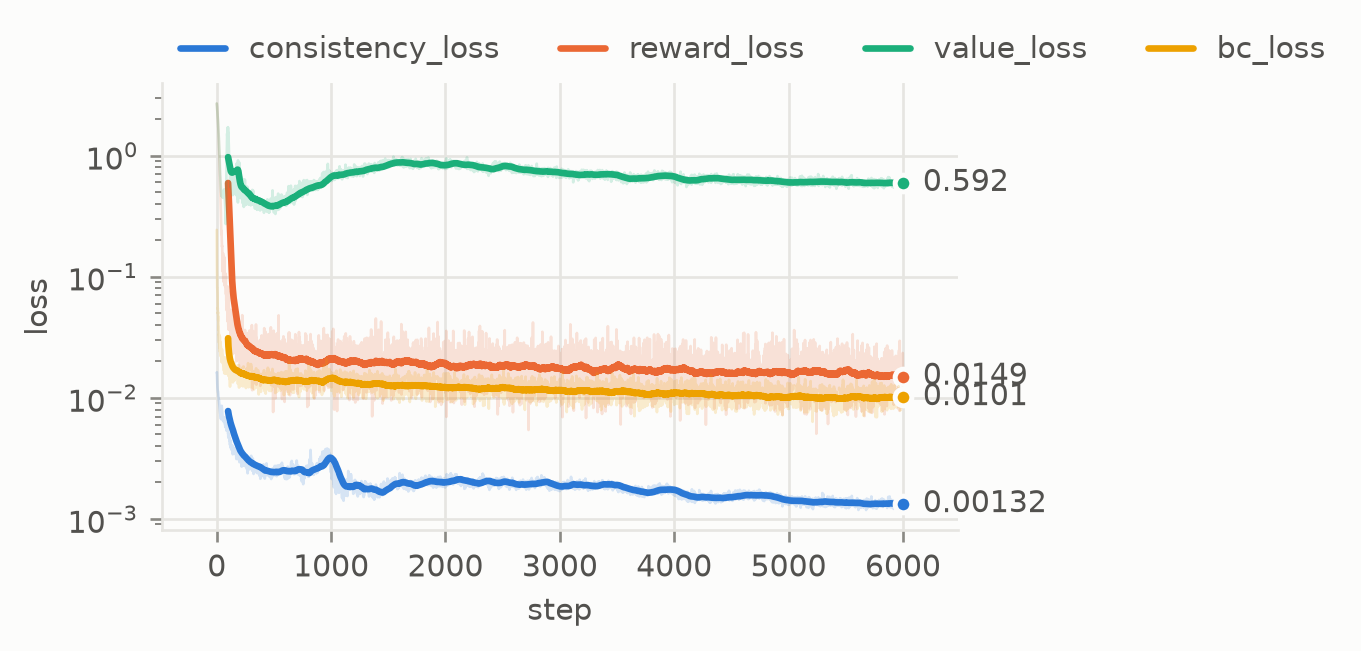

In [3]:
def pack_episodes(episodes):
    obs_l, act_l, rew_l, term_l, starts_l = [], [], [], [], []
    offset, pad_steps = 0, (HORIZON - 1) * CHUNK
    for ep in episodes:
        o = (ep["observations"][0] - obs_mean) / obs_std
        a = (ep["actions"][0] / act_scale).clamp(-1, 1)
        r, t = ep["rewards"][0], ep["terminated"][0]
        n_trans = o.shape[0] - 1
        if n_trans < CHUNK:
            continue
        obs_l.append(torch.cat([o, o[-1:].expand(pad_steps, -1)], dim=0))
        act_l.append(torch.cat([a[:-1], torch.zeros(pad_steps + 1, A)], dim=0))
        rew_l.append(torch.cat([r[:-1], torch.zeros(pad_steps + 1)], dim=0))
        term_l.append(torch.cat([t[:-1], torch.ones(pad_steps + 1, dtype=torch.bool)], dim=0))
        starts_l.append(torch.arange(offset, offset + n_trans - CHUNK + 1))
        offset += o.shape[0] + pad_steps
    return tuple(torch.cat(x, dim=0).to(device) for x in (obs_l, act_l, rew_l, term_l, starts_l))


tr_data = pack_episodes(train_eps)
va_data = pack_episodes(val_eps)
obs_offsets = torch.arange(HORIZON + 1, device=device) * CHUNK
step_offsets = torch.arange(HORIZON * CHUNK, device=device)


def sample_windows(data, batch_size):
    obs, act, rew, term, starts = data
    s = starts[torch.randint(len(starts), (batch_size,), device=device)]
    o_idx = s[:, None] + obs_offsets[None]
    st_idx = s[:, None] + step_offsets[None]
    return (
        obs[o_idx],
        act[st_idx].view(batch_size, HORIZON, A_CHUNK),
        rew[st_idx].view(batch_size, HORIZON, CHUNK).sum(-1),
        term[st_idx].view(batch_size, HORIZON, CHUNK).any(-1).float(),
    )


model = TDMPC2(
    state_encoder(D, latent_dim=128, hidden_dim=256),
    action_dim=A_CHUNK,
    latent_dim=128,
    mlp_dim=256,
    vmin=-1.0,
    vmax=1.0,
    discount=0.95,
    consistency_coef=5.0,
    reward_coef=2.0,
    value_coef=1.0,
    episodic=True,
).to(device)
STEPS = 6000
opt = torch.optim.Adam(model.param_groups(5e-4, encoder_lr_scale=1.0))
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS, eta_min=5e-5)

log = {k: [] for k in ("consistency_loss", "reward_loss", "value_loss", "bc_loss")}
tic = time.perf_counter()
model.train()
for _ in range(STEPS):
    obs, act, rew, term = sample_windows(tr_data, 256)
    out = model(obs, act, rew, term)
    z0 = model.encode(obs[:, :1])[:, 0]
    _, pi_info = model.pi(z0)
    bc_loss = F.mse_loss(pi_info["mean"], act[:, 0]) + 0.05 * (pi_info["log_std"] + 4.5).square().mean()
    rand_a = torch.rand_like(act[:, 0]) * 2 - 1
    zeros = torch.zeros_like(rew[:, 0])
    ood_q = model.soft_ce(model.q(z0.detach(), rand_a), zeros).mean()
    ood_r = model.soft_ce(model.reward(torch.cat([z0.detach(), rand_a], dim=-1)), zeros).mean()
    loss = out["loss"] + 25.0 * bc_loss + 0.05 * (ood_q + ood_r)
    opt.zero_grad()
    loss.backward()
    model.clip_grad_norm(20.0)
    opt.step()
    sched.step()
    model.update_target(0.99)
    log["bc_loss"].append(bc_loss.item())
    for key in ("consistency_loss", "reward_loss", "value_loss"):
        log[key].append(out[key].item())

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
print(f"{n_params:.2f}M parameters, {STEPS} updates in {(time.perf_counter() - tic) / 60:.1f} min")
plots.curves(log, smooth=100)

## Held-out dynamics and value check

Before touching the simulator, check whether the world model predicts 3-chunk (9-step) latent rollouts better than persistence and shuffled actions on the 200 held-out validation episodes, and verify that its Q and reward heads separate demonstration actions from random actions.

3-chunk latent MSE  TD-MPC2: 0.00321  persistence: 0.01234  shuffled: 0.01682
predicted reward    all: 0.008  at goal: 0.693  |  predicted Q  demo: 0.469  at goal: 0.941  random: 0.002


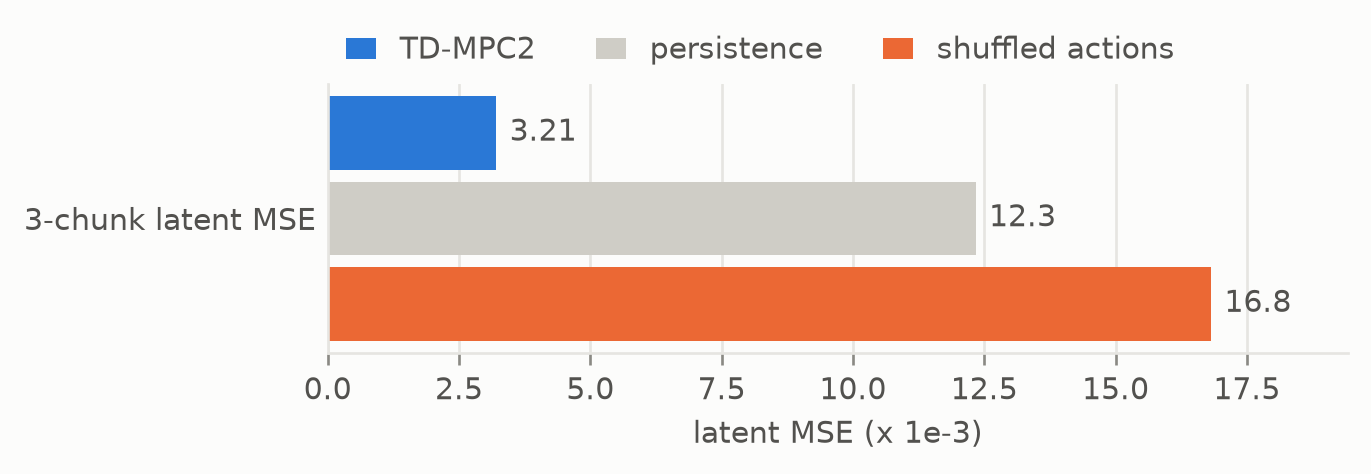

In [4]:
model.eval()
with torch.no_grad():
    obs, act, rew, _ = sample_windows(va_data, 1024)
    z = model.encode(obs)
    z_hat, z_shuf = z[:, 0], z[:, 0]
    perm = torch.randperm(len(act), device=device)
    for t in range(HORIZON):
        z_hat = model.predict(z_hat, act[:, t])
        z_shuf = model.predict(z_shuf, act[perm, t])
    mse_real = (z_hat - z[:, HORIZON]).square().mean().item()
    mse_pers = (z[:, 0] - z[:, HORIZON]).square().mean().item()
    mse_shuf = (z_shuf - z[:, HORIZON]).square().mean().item()
    r_all = model.two_hot_inv(model.reward(torch.cat([z[:, 0], act[:, 0]], dim=-1)))
    q_real = model.q(z[:, 0], act[:, 0], "mean")
    q_rand = model.q(z[:, 0], torch.rand_like(act[:, 0]) * 2 - 1, "mean")

print(f"3-chunk latent MSE  TD-MPC2: {mse_real:.5f}  persistence: {mse_pers:.5f}  shuffled: {mse_shuf:.5f}")
print(
    f"predicted reward    all: {r_all.mean():.3f}  at goal: {r_all[rew[:, 0] > 0].mean():.3f}  |  "
    f"predicted Q  demo: {q_real.mean():.3f}  at goal: {q_real[rew[:, 0] > 0].mean():.3f}  random: {q_rand.mean():.3f}"
)
plots.bars(
    {
        "3-chunk latent MSE": {
            "TD-MPC2": mse_real * 1e3,
            "persistence": mse_pers * 1e3,
            "shuffled actions": mse_shuf * 1e3,
        }
    },
    xlabel="latent MSE (x 1e-3)",
    baseline="persistence",
)

## Evaluation in OCBench

32 new seeded episodes (two 16-lane batches) for three policies executed with `RecedingHorizon`: MPPI planning 3 action chunks (9 control steps) ahead in latent space, the policy prior alone (its mean action, no search), and random actions. Resetting MPPI's Gaussian at each replan keeps its search anchored to the current chunk rather than drifting across grasp transitions.

TD-MPC2 + MPPI  success 56.2%   mean steps 146.0


policy prior    success 43.8%   mean steps 152.4


random actions  success 3.1%   mean steps 181.6


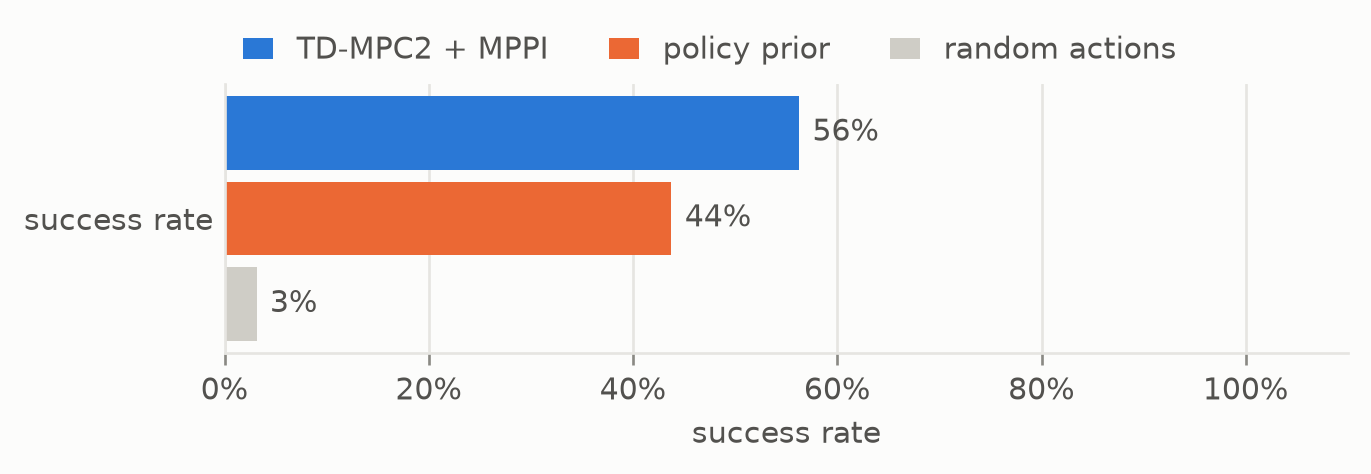

In [5]:
planner = MPPI(
    horizon=HORIZON,
    action_dim=A_CHUNK,
    num_samples=128,
    num_elites=16,
    num_pi_trajs=64,
    iterations=2,
    min_std=0.005,
    max_std=0.05,
    temperature=5.0,
)


def evaluate(mode, seeds=(1000, 2000), capture_frames=0):
    all_success, all_steps, clip = [], [], None
    with torch.no_grad():
        for i, seed in enumerate(seeds):
            obs = world.reset(seed=seed)

            def plan_fn(o):
                z = model.encode(((o.to(device) - obs_mean_d) / obs_std_d)[:, None])
                if mode == "prior":
                    return model.pi(z[:, 0])[1]["mean"][:, None].cpu()
                planner.reset()
                return planner(model, z, explore=False).cpu()

            controller = RecedingHorizon(plan_fn, action_dim=A, execute=1)
            success = torch.zeros(ENVS, dtype=torch.bool)
            steps = torch.zeros(ENVS)
            frames = [world.render_frame()[:capture_frames]] if (capture_frames and i == 0) else []
            while not world.transition.done.all():
                active = ~world.transition.done
                if mode == "random":
                    action = torch.rand(ENVS, A) * 2 - 1
                else:
                    action = (controller(obs) * act_scale).clamp(-1, 1)
                obs = world.step(action)
                success |= world.transition.success
                steps += active.float()
                if frames:
                    frames.append(world.render_frame()[:capture_frames])
            all_success.append(success)
            all_steps.append(steps)
            if frames:
                clip = (torch.stack(frames, dim=1), success[:capture_frames], steps[:capture_frames])
    success_cat = torch.cat(all_success)
    steps_cat = torch.cat(all_steps)
    return success_cat.float().mean().item(), steps_cat.mean().item(), clip


results, clip = {}, None
for label, mode, cap in (
    ("TD-MPC2 + MPPI", "mppi", 4),
    ("policy prior", "prior", 0),
    ("random actions", "random", 0),
):
    rate, mean_steps, out_clip = evaluate(mode, capture_frames=cap)
    results[label] = rate
    if out_clip is not None:
        clip = out_clip
    print(f"{label:15s} success {rate:.1%}   mean steps {mean_steps:5.1f}")

plots.bars({"success rate": results}, xlabel="success rate", baseline="random actions")

Four of the planned evaluation episodes.


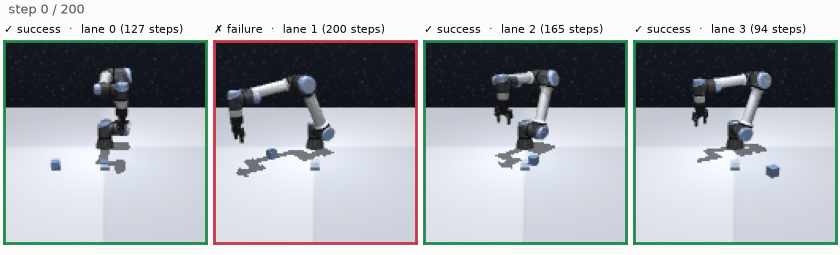

In [6]:
video, clip_success, clip_steps = clip
idx = list(range(0, video.size(1) - 1, 4)) + [video.size(1) - 1]
titles = [f"lane {i} ({int(clip_steps[i])} steps)" for i in range(video.size(0))]
world.close()
plots.episodes(video[:, idx], success=clip_success, titles=titles, ncols=4, size=2.1, fps=8, frame_steps=idx)

This is a small offline baseline (6,000 updates on one lite task). Larger runs can train on all shards or fine-tune online in GPU-parallel MJWarp (`OCBench` selects MJWarp automatically when CUDA and `mujoco_warp` are available). Visual multi-camera datasets work the same way: `load_ocbench("visual-block-single-task1-v0", num_shards=1, camera="front", size=64)` packs sparse `observation_interval=25` chunks alongside `OCBench("visual-block-single-task1-v0", size=64)`, and `list_envs(backend="ocbench")` lists all 28 registered tasks.